# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [ ]:
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Define Original Priors

In [3]:
NSamps = 8000;

priorTheta = Array{Any}(undef, 13);
priotY0 = Array{Any}(undef, 3);

priorTheta[1] = Normal(40.92, 10); priorTheta[2] = Normal(51.23, 10); priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

global sampsTh = zeros(NSamps, 13);
global sampsY0 = zeros(NSamps, 3);

Random.seed!(687865443); 

for i in 1:13
    sampsTh[:,i] = rand(priorTheta[i], NSamps);
end
for i in 1:3
    sampsY0[:,i] = rand(priotY0[i], NSamps);
end

sampsTh[:,2] .= 51.23; # T1 of Pyruvate is fixed since it is irrelevant for the model for the problem and can be estimated with experiments without cells. 
sampsTh[:,13] .= 15; # This will be re-writen with the empirical value once extracted from data

In [4]:
bounds = [zeros(12), zeros(12)];
boundY0 = [[0, 0, 0], [1600, 4e4, 1600]];
for i in 1:12
    if i >= 3
        if priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4) >= 0
            bounds[1][i] = priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4);
        else
            bounds[1][i] = 0;
        end
        if priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4) <= 2
            bounds[2][i] = priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4);
        else
            bounds[2][i] = 2;
        end
    elseif i == 1
        bounds[1][i] = priorTheta[i].μ - (priorTheta[i].σ*4);
        bounds[2][i] = priorTheta[i].μ + (priorTheta[i].σ*4);
    elseif i == 2
        bounds[1][i] = 51.23;
        bounds[2][i] = 51.23;
    end
end

In [15]:
# priorInfer =  Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame))
priorInfer =  Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame))



8000×16 Matrix{Float64}:
 41.1949  51.23  0.00772956  0.0186012  …  108.217   29811.1    503.579
 51.6101  51.23  0.00555101  0.0274524      92.1469  26464.8    606.874
 35.1197  51.23  0.00359025  0.022186       99.0307  24812.1   1052.16
 42.6028  51.23  0.00456304  0.0212256      85.5154  19561.7    687.445
 47.9692  51.23  0.00240846  0.0221916     728.696   19468.1     96.2662
 34.1855  51.23  0.00208756  0.0264356  …  966.98    13295.4     51.994
 41.3952  51.23  0.00365566  0.0360747     674.542   13456.3     34.8437
 43.0616  51.23  0.00375345  0.0534735     913.116   13598.4     19.7182
 40.0763  51.23  0.00456141  0.0192255     623.161    8511.54    89.1608
 38.109   51.23  0.00208587  0.0394897     793.988   24283.8     29.0393
  ⋮                                     ⋱                         ⋮
 49.7357  51.23  0.00225835  0.0386458      64.7826  17986.2    729.165
 30.5304  51.23  0.00610859  0.0242321     830.675   16655.5    477.217
 50.8069  51.23  0.00687396  0.02793   

# Intuition Driven Experimental Design (ID)

## Generate Repression Curve with Prior Means to Identify "Good" Sampling Point
Will do this for each posterior to assess better the sampling. At this iteration, we will choose a point half way through the peak and the plateau, since the initial value of 3.2 is so already quite close to the peak. 

In [16]:
tsC2 = vcat(0, collect(15:5:395));
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);

In [17]:
Pyrs = collect(0:0.1:40);

Sims = Array{Any}(undef, length(Pyrs));

for i in 1:length(Pyrs)
    ivss = [Pyrs[i].*1000, 0, 0, mean(priorInfer[:,14], dims=1)[1], mean(priorInfer[:,15], dims=1)[1], mean(priorInfer[:,16], dims=1)[1], 0, 0, 0, 0, 0, Pyrs[i].*1000, 0, Pyrs[i].*1000*(priorInfer[1,13]*0.12)];
    
    SimulsAll1, SimulsAll2, SimulsAll3  = PyruvateHP_NMR_SolveAllCp(ts, hcat(mean(priorInfer[:,1:13], dims=1), 0), ivss, samps);
    Sims[i] = SimulsAll1;
end


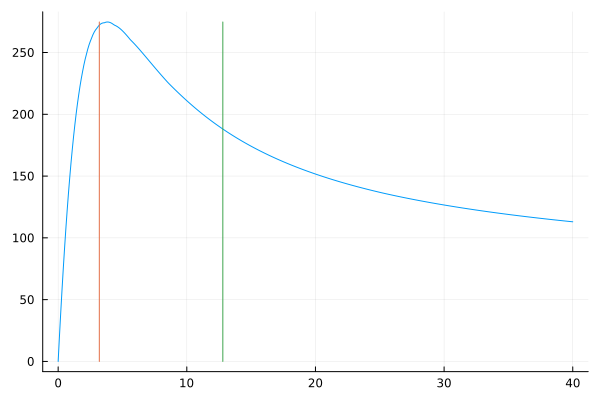

In [18]:
# If we consider for the curve the maximum value on the lactate curve
Lacs = zeros(length(Pyrs));

for i in 1:length(Pyrs)
    Lacs[i] = maximum(Sims[i][:,13,1]);
end

plot(Pyrs, Lacs, label = "")
plot!([3.2, 3.2],[0, maximum(Lacs)], label = "")
plot!([12.8, 12.8],[0, maximum(Lacs)], label = "")

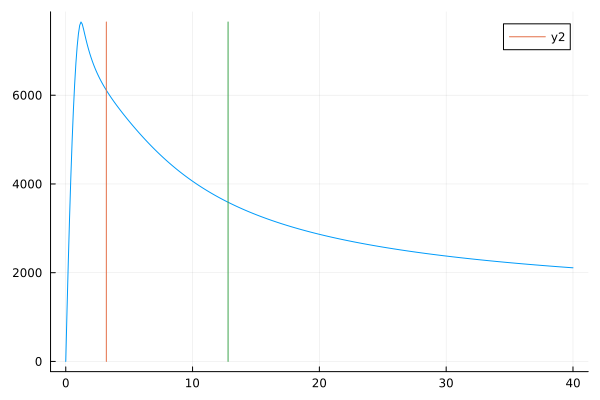

In [19]:
# If we consider for the curve the sum of all data points of the lactate curve

Lacs = zeros(length(Pyrs));

for i in 1:length(Pyrs)
    Lacs[i] = sum(Sims[i][:,13,1]);
end

plot(Pyrs, Lacs, label = "")
plot!([3.2, 3.2],[0, maximum(Lacs)])
plot!([12.8, 12.8],[0, maximum(Lacs)], label = "")

In [21]:
PyrCons = [12.8]

1-element Vector{Float64}:
 12.8

In [24]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:13];
global sampsY0 = priorInfer[:,14:end];
CompRepUtil_Entro_OEDmc(PyrCons)

165.60299862073333

## Simulate Experiment Prio Prediction

In [11]:
simsPrior = Array{Any}(undef, 8000);

tsC2 = vcat(0, collect(15:5:395));
for i in 1:8000
    ts = 0:tsC2[end];
    ivss = [round(PyrCons[1], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(PyrCons[1], digits = 1)*1000, 0, round(PyrCons[1], digits = 1)*1000*(priorInfer[1,13]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);
    simsPrior[i] = SimulsAll;
end

UndefVarError: UndefVarError: `priorInfer` not defined

In [12]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];
for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end

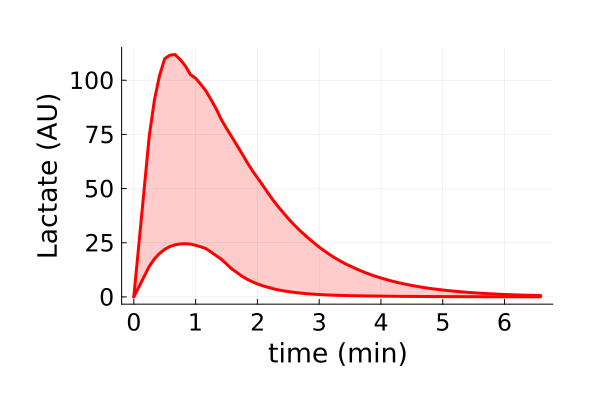

In [13]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "red", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "red", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="red", fillalpha=0.2)

# .................................................... PERFORM EXPERIMENT ....................................................

80 uL of pyruvate + 170 uL of media from the 40 mM solution 
<br>
40 uL of pyruvate + 210 uL of media from the 80 mM solution

# Extract Experimental Data 3.2 mM and 12.8 mM

In [ ]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_12-8mMPyr_Dat.csv"];
conce = [3.2, 12.8];

In [23]:
Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1])

Base.IOError: IOError: stat("D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\3Mil_3-2mMPyr_Dat.csv"): unknown error (UNKNOWN)

# Simulate Experiment Prior Prediction

In [17]:
simsPrior = Array{Any}(undef, 8000);
sampsTh[:,13] .= dat["ScFms"][end];

tsC2 = dat["sts"];
for i in 1:8000
    tsC2 = dat["sts"][:,end];
    ts = 0:tsC2[end];
    ivss = [round(conce[end], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);

    simsPrior[i] = SimulsAll;
end

In [18]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


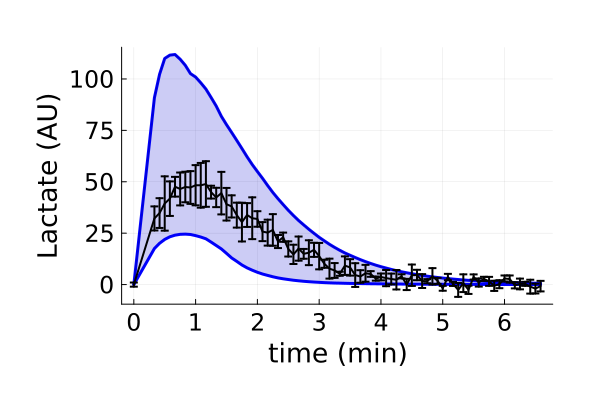

In [19]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "")

# MLE to obtain a good first guess for inference

In [20]:
function ObjectFunctMECp_Multi_MLE(p)

    # Define parameter vectors for each amount of cells (last parameter is a time delay, not used in here)
    
    obj = 0;
    
    for i in 1:length(dat["stsl"])
        pD2 = vcat(p[1:end-3], dat["ScFms"][i], 0);

        # Define time vector
        t2cor = dat["sts"][:,i];

        # Define equaly-spaced time vector
        ts1 = collect(0:t2cor[end]);

        # Define initial value for simulation (use of experimental mean)
        ivss1 = [dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), 0, dat["Means"][1,i,2]/(dat["ScFms"][i]*0.12), p[end-2], p[end-1], p[end], 0, 0, 0, 0, 0, dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), dat["Means"][1,i,2], dat["Means"][1,i,1]];

        # Convert sampling vector to integer to extract correct elements from simulation
        samps1 = convert.(Int, t2cor);

        # Simulate
        SimOnTime1, SimOffTime1, SimAll1  = PyruvateHP_NMR_SolveAllCp(ts1, pD2, ivss1, samps1);
    
        # mm11 = sum((-1/2) .* (log(2*pi) .+ log.((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2) .+ (((SimOnTime1[:,14]/maximum(dat["Means"][:,i,1])) .- 
        #                 (dat["Means"][:,i,1]/maximum(dat["Means"][:,i,1]))).^2)./((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2)));
        mm11 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,1].^2) .+ ((SimOnTime1[:,14] .- dat["Means"][:,i,1]).^2)./(dat["Erros"][:,i,1].^2)));
        mm22 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,2].^2) .+ ((SimOnTime1[:,13] .- dat["Means"][:,i,2]).^2)./(dat["Erros"][:,i,2].^2)));
        # println(mm11)
        # obj = (mm21+mm22)*(mm11+mm12);
        if p[end-2] >= p[end-1]
            mm22 = mm22*10;
        end
        # obj = -(mm22)+obj;
        obj = -(mm22)+sqrt(abs(mm11))+obj;
    end
    
    return(obj)

end

ObjectFunctMECp_Multi_MLE (generic function with 1 method)

In [21]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE(p)

2220.241947891393

In [37]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:12], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*4, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.52 secs, 40 evals, 20 steps, improv/step: 0.450 (last = 0.4500), fitness=570.310613331
1.02 secs, 95 evals, 52 steps, improv/step: 0.462 (last = 0.4688), fitness=570.310613331
1.69 secs, 151 evals, 87 steps, improv/step: 0.414 (last = 0.3429), fitness=570.310613331
2.19 secs, 222 evals, 140 steps, improv/step: 0.364 (last = 0.2830), fitness=515.619311070
2.97 secs, 290 evals, 195 steps, improv/step: 0.364 (last = 0.3636), fitness=515.619311070
3.49 secs, 364 evals, 254 steps, improv/step: 0.343 (last = 0.2712), fitness=515.619311070
3.99 secs, 431 evals, 308 steps, improv/step: 0.315 (last = 0.1852), fitness=515.619311070
4.50 secs, 458 evals, 331 steps, improv/step: 0.314 (last = 0.3043), fitness=515.619311070
5.00 secs, 526 evals, 390 steps, improv/step: 0.305 (last = 0.2542), fitn

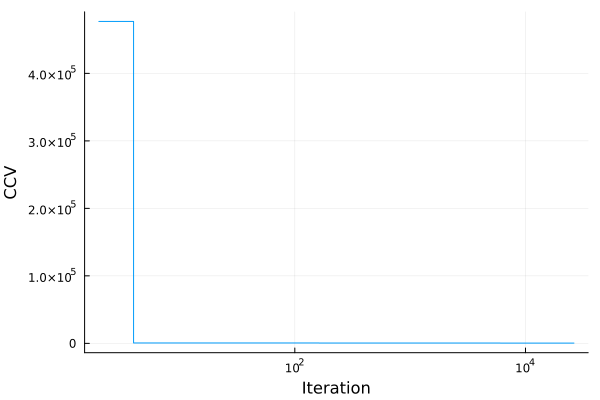

In [38]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

In [39]:
# Extract Parameter Vector
parfitT = zeros(15, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind]

15-element Vector{Float64}:
    44.32446919794743
    51.23
     0.004410378721099376
     0.023049069749763423
     0.13870411136277544
     0.24108760791681694
     1.6560415889979012
     0.931176256549993
     0.613800746548275
     0.03954411677535963
     1.0716077345767727
     0.0034190967720603305
    73.81033469808163
 30085.727528636435
  1213.739249179959

In [40]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMTRRCmp_Exper_ID1.jld2", "FitsT",FitsT)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_ID1.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

┌ Warning: Attempting to store var"#101#102".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [22]:
ppT = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_ID1.jld2")["resMMat"][:,1]


15-element Vector{Float64}:
    44.32446919794743
    51.23
     0.004410378721099376
     0.023049069749763423
     0.13870411136277544
     0.24108760791681694
     1.6560415889979012
     0.931176256549993
     0.613800746548275
     0.03954411677535963
     1.0716077345767727
     0.0034190967720603305
    73.81033469808163
 30085.727528636435
  1213.739249179959

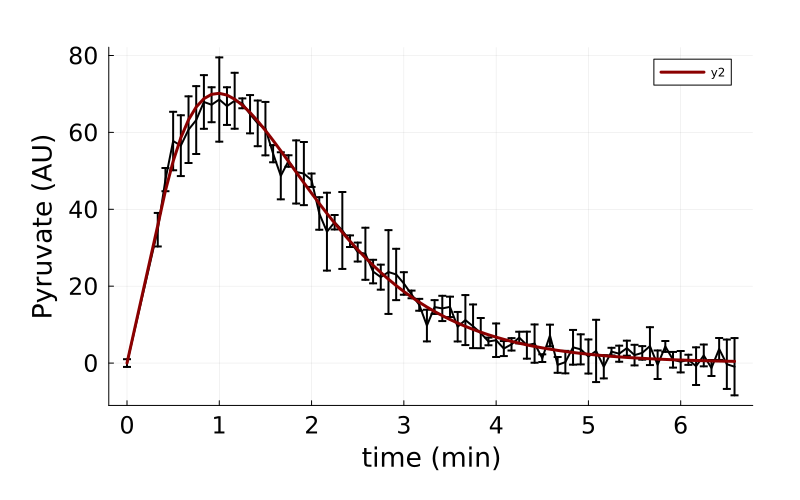

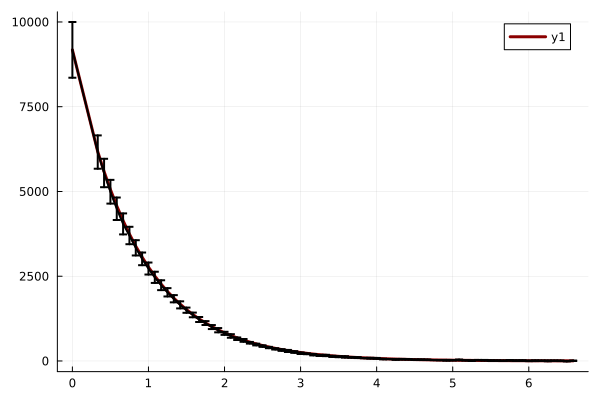

In [23]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,1];
ts = 0:tsC2[end];
ivss = [round(conce[1], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[1], digits = 1)*1000, 0, round(conce[1], digits = 1)*1000*(dat["ScFms"][1]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][1], 0), ivss, samps);

pps = plot(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)


ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

display(ps)

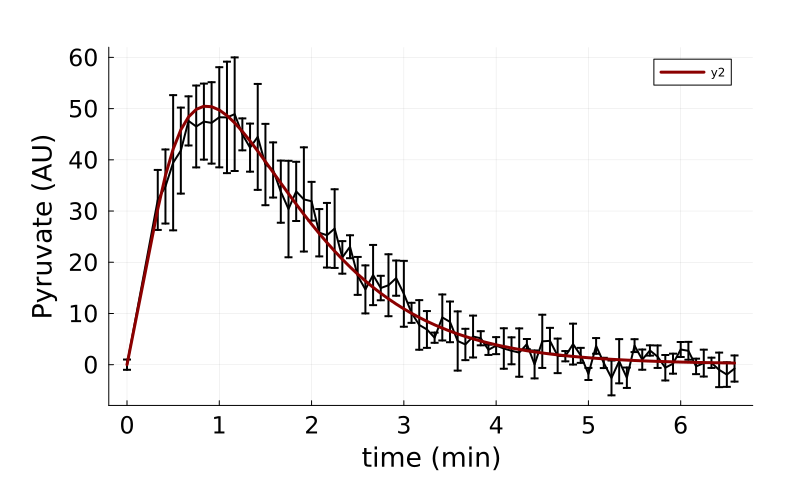

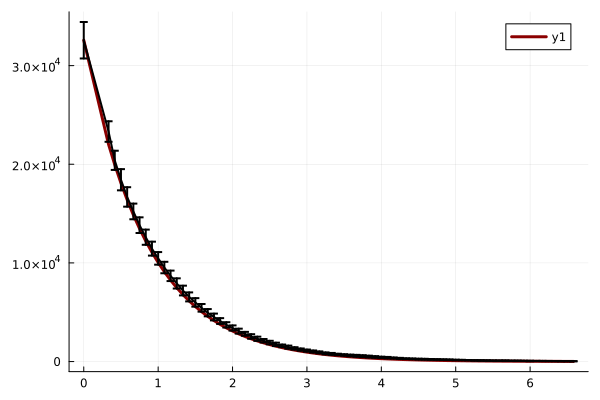

In [24]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,end];
ts = 0:tsC2[end];
ivss = [round(conce[end], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][end], 0), ivss, samps);

pps = plot(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)

ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,end]./60, dat["Means"][:,end,1], yerror = dat["Erros"][:,end,1], linewidth = 2, colour = "black", label = "")

display(ps)

## Compute structure for Stan's initial guess

In [25]:
preTrans = zeros(14);

preTrans[1] = (ppT[1]-40.92)/10; 
preTrans[2] = (ppT[3]-0.0055)/0.0055; 
preTrans[3] = (ppT[4]-0.0275)/0.0275;          
preTrans[4] = (ppT[5]-0.045)/0.045;
preTrans[5] = (ppT[6]-0.45)/0.45;
preTrans[6] = (ppT[7]-0.95)/0.95;
preTrans[7] = (ppT[8]-0.95)/0.95;
preTrans[8] = (ppT[9]-0.95)/0.95;
preTrans[9] = (ppT[10]-0.0085)/0.0085;
preTrans[10] = (ppT[11]-0.95)/0.95;
preTrans[11] = (ppT[12]-0.0029)/0.0029;


preTrans[12] = (ppT[13]-650)/260;
preTrans[13] = (ppT[14]-16000)/6400;
preTrans[14] = (ppT[15]-550)/275;

In [26]:

samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict(samps, names, 4)

4-element Vector{Dict{String, Any}}:
 Dict("kbnE" => 3.65224903239525, "LDH" => 2.4135972697453054, "kin" => -0.19811295980011343, "ki" => 0.12800814165976082, "kunE" => -0.35389395100181575, "kpl" => -0.1618520090995119, "NADH" => -2.216114097315071, "kup" => -0.019814466789480973, "T1_X" => 0.3404469197947428, "kbp" => 0.7432016726293698…)
 Dict("kbnE" => 3.65224903239525, "LDH" => 2.4135972697453054, "kin" => -0.19811295980011343, "ki" => 0.12800814165976082, "kunE" => -0.35389395100181575, "kpl" => -0.1618520090995119, "NADH" => -2.216114097315071, "kup" => -0.019814466789480973, "T1_X" => 0.3404469197947428, "kbp" => 0.7432016726293698…)
 Dict("kbnE" => 3.65224903239525, "LDH" => 2.4135972697453054, "kin" => -0.19811295980011343, "ki" => 0.12800814165976082, "kunE" => -0.35389395100181575, "kpl" => -0.1618520090995119, "NADH" => -2.216114097315071, "kup" => -0.019814466789480973, "T1_X" => 0.3404469197947428, "kbp" => 0.7432016726293698…)
 Dict("kbnE" => 3.65224903239525, "LDH" =>

In [27]:
ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 3.65225
  "LDH"  => 2.4136
  "kin"  => -0.198113
  "ki"   => 0.128008
  "kunE" => -0.353894
  "kpl"  => -0.161852
  "NADH" => -2.21611
  "kup"  => -0.0198145
  "T1_X" => 0.340447
  "kbp"  => 0.743202
  "kr"   => 0.178999
  "NAD"  => 2.20089
  "kun"  => -0.46425
  "kbn"  => 2.08231

# Inference

In [28]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_ID1_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 600, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [ ]:
# modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit2.stan";

In [29]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_ID1_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(600,600,600,600,600,600,600,600,600,600); thin=(1,1,1,1,1,1,1,1,1,1); 14000 iterations saved.

Warmup took (79104, 82438, 83420, 67698, 79467, 86511, 74452, 58752, 82557, 46836) seconds, 206 hours total
Sampling took (120970, 105477, 99488, 114061, 90074, 98922, 114138, 104455, 114414, 85712) seconds, 291 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -4.0e+02  7.9e-02  3.1e+00  -4.0e+02  -4.0e+02  -3.9e+02  1.6e+03  1.5e-03  1.0e+00
accept_stat__    9.4e-01  5.9e-03  1.1e-01   7.2e-01   9.8e-01      1.00  3.7e+02  3.5e-04  1.0e+00
stepsize__       7.5e-03  7.6e-04  2.8e-03   3.8e-03   7.2e-03     0.012  1.3e+01  1.2e-05  1.3e+00
treedepth__      8.8e+00  1.0e-01  7.3e-01   8.0e+00   9.0e+00        10  5.3e+01  5.0e-05  1.1e+00
n_leapfrog__     5.9e+02  3.2e+01  2.7e+02   2.6e

(0, [-395.292 0.977761 … 20633.2 455.228; -395.292 0.0 … 20633.2 455.228; … ; -397.996 0.989636 … 11772.3 780.264; -395.623 0.990682 … 19352.0 830.14;;; -401.466 0.255346 … 30085.7 1213.74; -401.466 0.0 … 30085.7 1213.74; … ; -406.958 0.954608 … 14392.3 974.356; -400.055 0.989761 … 14038.0 443.993;;; -404.912 0.89285 … 15178.5 402.345; -404.912 0.0 … 15178.5 402.345; … ; -398.74 0.908796 … 25469.1 538.943; -402.381 0.998931 … 11314.1 224.963;;; -400.698 0.529477 … 32441.6 1253.72; -400.698 0.0 … 32441.6 1253.72; … ; -401.701 0.999859 … 12724.4 586.76; -397.466 0.812285 … 10750.2 797.176;;; -394.766 0.98043 … 11823.0 344.917; -394.766 0.0 … 11823.0 344.917; … ; -397.249 0.959804 … 15872.4 545.836; -393.476 0.847471 … 12893.1 668.21;;; -400.935 0.997577 … 9677.57 271.235; -400.935 0.0 … 9677.57 271.235; … ; -398.863 0.999853 … 30027.1 330.596; -397.438 0.965699 … 5579.5 220.214;;; -398.081 0.968655 … 15843.4 1004.84; -398.081 0.0 … 15843.4 1004.84; … ; -399.819 0.555641 … 13599.8 1181.13

In [30]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PyrCompetitiveRepressionInferExp_ID1_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

In [31]:
poster = vcat(chns[401:end, end-15:end, 1], chns[401:end, end-15:end, 2], chns[401:end, end-15:end, 3], chns[401:end, end-15:end, 4], chns[401:end, end-15:end, 5], 
              chns[401:end, end-15:end, 6], chns[401:end, end-15:end, 7], chns[401:end, end-15:end, 8], chns[401:end, end-15:end, 9], chns[401:end, end-15:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID1_Try1.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID1_Try1.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID1_Try1.csv"

In [32]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_ID1_Try1.csv", DataFrame))

10000×16 Matrix{Float64}:
 45.2333  51.23  0.00690629  0.0218059  …  618.122   20403.8    752.12
 48.3183  51.23  0.00694028  0.0227119     402.374   13105.5    841.096
 40.3968  51.23  0.00310433  0.0190196     440.763    8268.83   266.318
 49.232   51.23  0.00555663  0.0230209     306.63    22971.8    766.596
 45.9219  51.23  0.0051498   0.0204843     205.375   22413.6    712.864
 49.844   51.23  0.00947429  0.0262187  …  424.344   14008.8    469.769
 46.836   51.23  0.00707995  0.0221575     453.454   26670.1    615.116
 48.0425  51.23  0.00974014  0.0214174     480.95    21831.7    563.386
 44.9581  51.23  0.00957295  0.0232837     782.681   18583.5    790.481
 44.6359  51.23  0.00826425  0.0230385     701.428   15639.4    784.976
  ⋮                                     ⋱                         ⋮
 47.0656  51.23  0.00448371  0.0233377      75.1879  26870.1    862.848
 43.1541  51.23  0.00578506  0.0201927      97.8729  23337.6    817.492
 52.3638  51.23  0.00432448  0.0279674     

# Plot Posterior VS Prior

In [33]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

In [34]:
priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

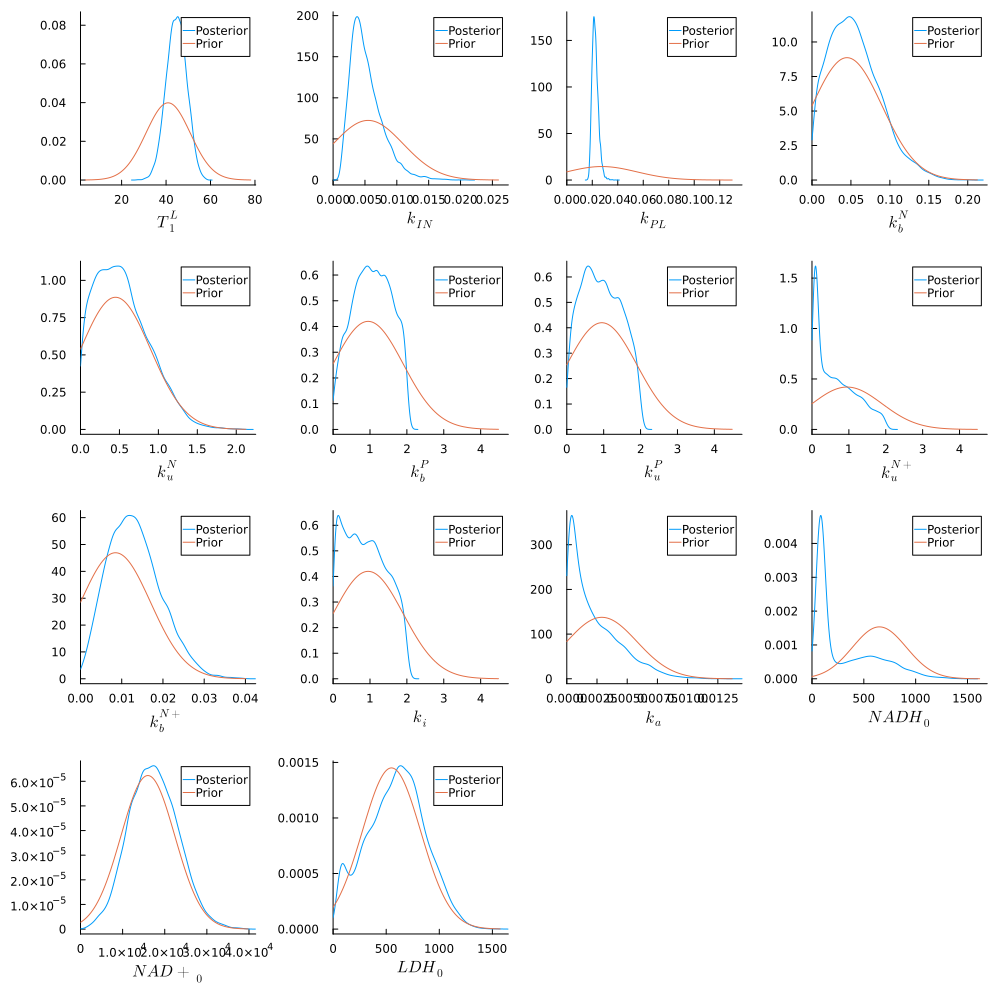

In [35]:
pp0 = plot(kde(poster[:,1]), label = "Posterior", xlabel = namess[1])
plot!(Normal(40.92, 10), label = "Prior")

pp1 = plot(kde(poster[:,3]), label = "Posterior", xlabel = namess[2])
plot!(Normal(0.0055, 0.0055), label = "Prior", xlim = (0, 0.0055+4*0.0055))

pp2 = plot(kde(poster[:,4]), label = "Posterior", xlabel = namess[3])
plot!(Normal(0.0275, 0.0275), label = "Prior", xlim = (0, 0.0275+4*0.0275))

pp3 = plot(kde(poster[:,5]), label = "Posterior", xlabel = namess[4])
plot!(Normal(0.045, 0.045), label = "Prior", xlim = (0, 0.045+4*0.045))

pp4 = plot(kde(poster[:,6]), label = "Posterior", xlabel = namess[5])
plot!(Normal(0.45, 0.45), label = "Prior", xlim = (0, 0.45+4*0.45))

pp5 = plot(kde(poster[:,7]), label = "Posterior", xlabel = namess[6])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp6 = plot(kde(poster[:,8]), label = "Posterior", xlabel = namess[7])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp7 = plot(kde(poster[:,9]), label = "Posterior", xlabel = namess[8])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp8 = plot(kde(poster[:,10]), label = "Posterior", xlabel = namess[9])
plot!(Normal(0.0085, 0.0085), label = "Prior", xlim = (0, 0.0085+4*0.0085))

pp9 = plot(kde(poster[:,11]), label = "Posterior", xlabel = namess[10])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp10 = plot(kde(poster[:,12]), label = "Posterior", xlabel = namess[11])
plot!(Normal(0.0029, 0.0029), label = "Prior", xlim = (0, 0.0029+4*0.0029))


pp11 = plot(kde(poster[:,14]), label = "Posterior", xlabel = namess[12])
plot!(Normal(650, 260), label = "Prior", xlim = (0, 650+4*260))

pp12 = plot(kde(poster[:,15]), label = "Posterior", xlabel = namess[13])
plot!(Normal(16000, 6400), label = "Prior", xlim = (0, 16000+4*6400))

pp13 = plot(kde(poster[:,16]), label = "Posterior", xlabel = namess[14])
plot!(Normal(550, 275), label = "Prior", xlim = (0, 550+4*275))

plot(pp0,pp1,pp2,pp3,pp4,pp5,pp6,pp7,pp8,pp9,pp10,pp11,pp12,pp13, size=(1000,1000), grid = false)

In [36]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,14:end]))))

21.55384108067285

In [37]:
using CairoMakie
using PairPlots
using DataFrames

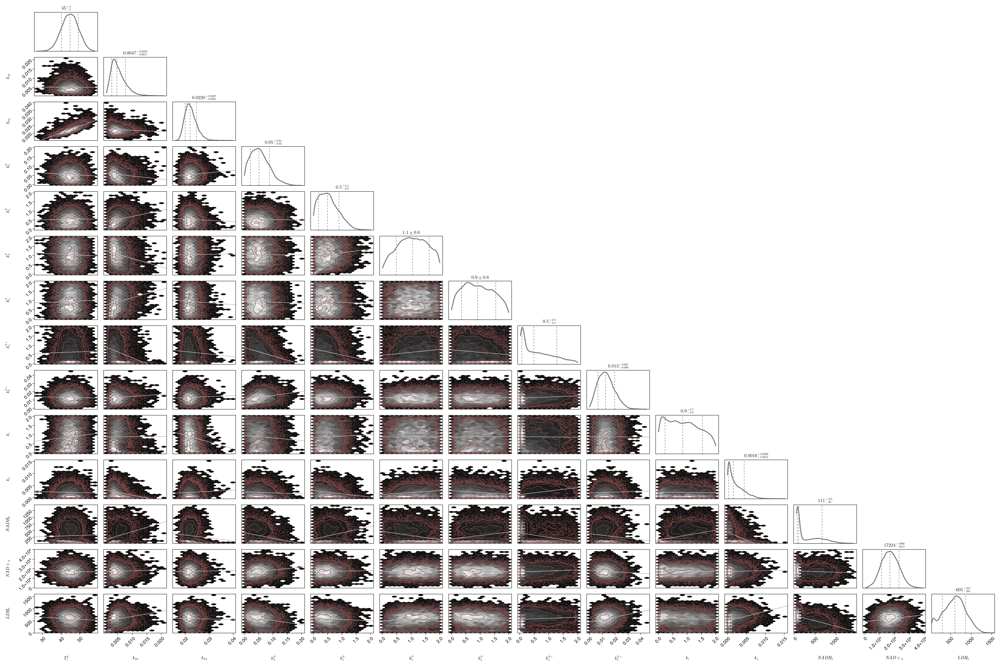

In [38]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,14:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_ID1Experiment.svg", fig)


fig

# Simulate Experiment Current Posterior

In [39]:
simsPoster = Array{Any}(undef, 8000, 2);

for j in 1:2
for i in 1:8000
    tsC2 = dat["sts"][:,j];
    ts = 0:tsC2[end];
    ivss = [dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, 0, poster[i,14], poster[i,15], poster[i,16], 0, 0, 0, 0, 0, dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, dat["Means"][1,j,1]];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster[i,1:12], dat["ScFms"][j], 0), ivss, samps);

    simsPoster[i,j] = SimulsAll;
end
end

### Experiment 1

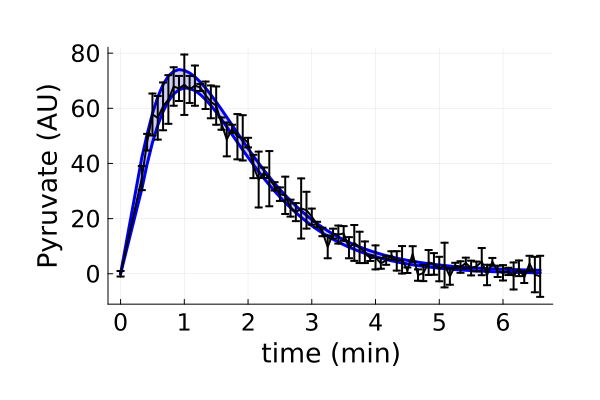

In [40]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,1][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "")

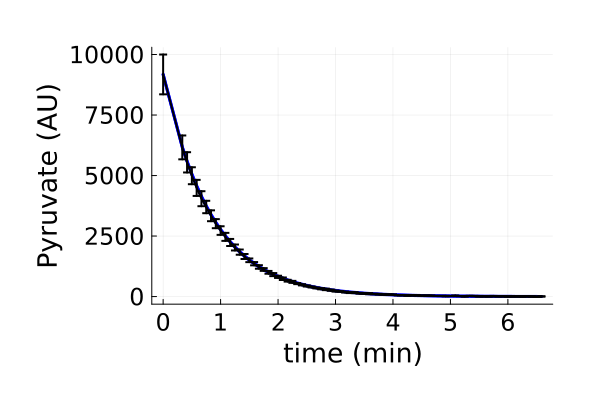

In [41]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,1][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

## Experiment 2

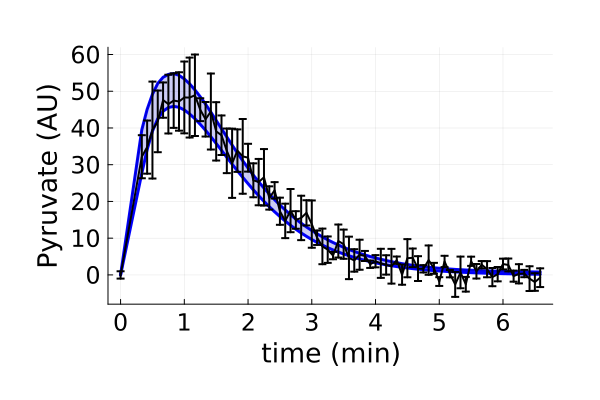

In [42]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,2][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,2], yerror = dat["Erros"][:,2,2], linewidth = 2, colour = "black", label = "")

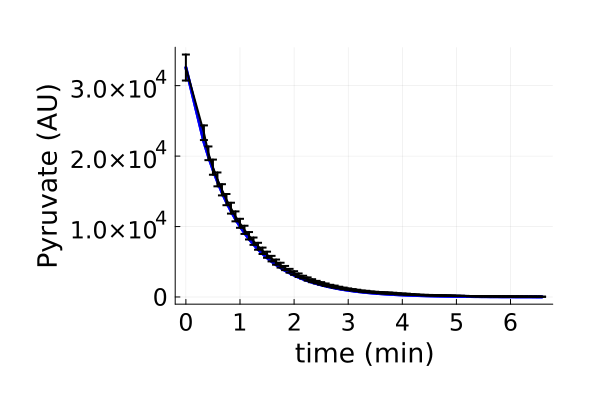

In [43]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,2][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")